# HydroGuard — modeling and review

This notebook explains the **saved** modeling workflow. It performs no fitting, tuning, test prediction or metric recomputation. Training reproduction is a separate development-only command. The original order, IDs, 70-feature contract, model choice and final evaluation remain frozen. See `01_eda.ipynb` for acquisition, cleaning and focused EDA. Existing historical artifacts are checked byte-for-byte before reading.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from hydroguard.features import FEATURE_CONTRACT
from hydroguard.reproduction import verify_review_history
from hydroguard.review import (
    baseline_table,
    candidate_table,
    saved_review,
    standardized_coefficients,
)
from hydroguard.splitting import load_split_lock
from hydroguard.tuning import SELECTION_RULE

ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "config/review-integrity-v1.json").is_file()
)
saved = saved_review(ROOT)
split = load_split_lock(ROOT / "artifacts/splits/phase2b-v1.json")
display(pd.Series(FEATURE_CONTRACT))

name                                        physical14-statistics5-v1
sensors             [PS1, PS2, PS3, PS4, PS5, PS6, EPS1, FS1, FS2,...
statistics                                 [mean, std, rms, min, max]
std_ddof                                                            0
dtype                                                         float64
names               [PS1__mean, PS1__std, PS1__rms, PS1__min, PS1_...
excluded_signals                                         [CE, CP, SE]
fitted_values                                                   False
dtype: object

## Deterministic contract and metadata boundary

Exactly 14 physical sensors contribute mean, population standard deviation (`ddof=0`), RMS, minimum and maximum, in the fixed sensor/statistic order: 70 float64 attributes. CE, CP and SE are excluded. These summaries are deterministic; no fitted values come from EDA. `cycle_id`, target, cooler/valve/accumulator conditions, stability and group identifiers remain metadata, never X. The strict loader rejects invalid shapes and values; no unstable cycles are silently removed.

In [2]:
outer = split["payload"]["memberships"]["outer"]
roles = pd.Series(
    {role: len(outer[f"{role}_cycle_ids"]) for role in ["development", "test", "excluded"]},
    name="Locked cycles",
)
display(
    roles,
    pd.DataFrame(
        [f["diagnostics"] for f in split["payload"]["memberships"]["inner"]], index=[1, 2, 3]
    ),
)

development    1328
test            339
excluded        538
Name: Locked cycles, dtype: int64

,train_cycles,validation_cycles,train_class_counts,validation_class_counts,minimum_original_cycle_distance,shared_nuisance_groups
1,607,442,"[453, 82, 72]","[290, 81, 71]",21,0
2,576,457,"[422, 82, 72]","[293, 82, 82]",21,0
3,607,429,"[463, 82, 62]","[263, 83, 83]",21,0


## Locked evaluation

Nuisance groups are `(cooler_condition_pct, valve_condition_pct, accumulator_pressure_bar)`, excluding target and stability. Outer SGKF uses 5 folds, shuffle=True, seed=2026; fold 2 is the reserved test (339, classes 133/103/103). Purging development candidates within 20 original cycle positions leaves 1,328 development and 538 excluded cycles. Inner SGKF has 3 saved folds and another original-ID gap 20. Scalers fit only inner training data. No split is generated here. Recorded groups are not proven independent experiments and gap 20 is not a validated physical decorrelation time. All cycles, including the test, were previously exposed in EDA.

## Baseline comparison — development only

These are historical unweighted fold means from the same locked CV. The dummy most-frequent baseline, scaled Logistic Regression and fixed Random Forest were compared before tuning. Pooled OOF scores are separate from fold means. This notebook does not require ignored local OOF CSV files.

In [3]:
display(baseline_table(saved))
display(
    pd.DataFrame(
        {
            name: model["pooled_oof"]["overall"]
            for name, model in saved["baseline"]["models"].items()
        }
    ).loc[["macro_f1", "balanced_accuracy", "recall_class_2"]]
)

,role,macro_f1,balanced_accuracy,recall_class_2
model,,,,
dummy,development CV baseline,0.259311,0.333333,0.000000
logistic_regression,development CV baseline,0.786481,0.798278,0.761730
random_forest,development CV baseline,0.781784,0.760207,0.653866


,dummy,logistic_regression,random_forest
macro_f1,0.25943,0.793653,0.79146
balanced_accuracy,0.333333,0.794917,0.763882
recall_class_2,0.0,0.75,0.665254


## Bounded tuning candidates and prespecified selection

Logistic Regression used C=[0.01,0.1,1,10,100] × class_weight=[None, balanced]. Random Forest used 12 distinct candidates sampled in advance with seed 2026 from the locked depth/leaf/features/weight space, plus its baseline reference. n_estimators=200, n_jobs=1 and seed=2026 remained fixed. Exactly 23 candidates and 69 fold fits were recorded; no search runs here. The locked configuration stores every concrete parameter. Selection maximized unweighted mean fold macro-F1, then class-2 recall, then the prespecified simplicity ordering. No test result changed that rule. The owner selected LR `lr_09`, C=100 and class_weight=None, before final test model access.

In [4]:
display(candidate_table(saved))
display(pd.Series(SELECTION_RULE, name="Prespecified rule"))
display(pd.Series(saved["tuning"]["selected"]["logistic_regression"]["parameters"]))

,family,parameters,eligible,reference,mean_macro_f1,mean_recall_class_2
candidate,,,,,,
lr_01,logistic_regression,"{'scaler': {'with_mean': True, 'with_std': Tru...",True,False,0.599789,0.461322
lr_02,logistic_regression,"{'scaler': {'with_mean': True, 'with_std': Tru...",True,False,0.674683,0.676609
lr_03,logistic_regression,"{'scaler': {'with_mean': True, 'with_std': Tru...",True,False,0.714988,0.680723
lr_04,logistic_regression,"{'scaler': {'with_mean': True, 'with_std': Tru...",True,False,0.749575,0.721324
lr_05,logistic_regression,"{'scaler': {'with_mean': True, 'with_std': Tru...",True,True,0.786481,0.761730
lr_06,logistic_regression,"{'scaler': {'with_mean': True, 'with_std': Tru...",True,False,0.800643,0.765942
lr_07,logistic_regression,"{'scaler': {'with_mean': True, 'with_std': Tru...",True,False,0.815738,0.782153
lr_08,logistic_regression,"{'scaler': {'with_mean': True, 'with_std': Tru...",True,False,0.829028,0.806396
lr_09,logistic_regression,"{'scaler': {'with_mean': True, 'with_std': Tru...",True,False,0.837084,0.822803


primary                          Maximum unweighted mean of three fold macro-F1...
secondary                        Maximum unweighted mean of three fold class-2 ...
ties                             Exact full-precision float equality; no roundi...
lr_simplicity                      Lower C, then class_weight=None before balanced
rf_simplicity                    Lower bounded max_depth (None last), larger mi...
final_tie                                   Lexicographically smaller candidate_id
reference_candidates_eligible                                                 True
eligibility                      All three fits and predictions successful, fin...
failures                         Structural/integrity violations stop the exper...
baseline_reproduction            Reference candidate OOF predictions must equal...
Name: Prespecified rule, dtype: object

scaler                    {'with_mean': True, 'with_std': True}
classifier    {'C': 100, 'l1_ratio': 0.0, 'solver': 'lbfgs',...
dtype: object

## Final model and historical test results

The complete StandardScaler/LR Pipeline was fit once on all 1,328 retained development cycles. The 538 outer-excluded cycles were neither fitted nor evaluated. Only the chosen model received the 339 test cycles in Phase 3B. The following values and confusion matrix are read from the existing report; they are not a new evaluation. Development selection scores are optimistic for model selection and are not combined with test results.

In [5]:
final = saved["final-test"]["test_results"]
display(
    pd.Series(
        {
            "development_selection_mean_macro_f1": saved["tuning"]["selected"][
                "logistic_regression"
            ]["mean_macro_f1"],
            "historical_test_macro_f1": final["overall"]["macro_f1"],
            "historical_test_balanced_accuracy": final["overall"]["balanced_accuracy"],
            "historical_test_class2_recall": final["overall"]["recall_class_2"],
        }
    )
)
display(pd.DataFrame(final["overall"]["per_class"]))
display(
    pd.DataFrame(
        final["overall"]["confusion_matrix"],
        index=["true 0", "true 1", "true 2"],
        columns=["pred 0", "pred 1", "pred 2"],
    )
)
display(
    pd.DataFrame(
        {
            flag: {
                k: stats[k]
                for k in [
                    "support",
                    "class_support",
                    "macro_f1",
                    "recall_class_2",
                    "undefined_metrics",
                ]
            }
            for flag, stats in final["stability"].items()
        }
    )
)

development_selection_mean_macro_f1    0.837084
historical_test_macro_f1               0.675047
historical_test_balanced_accuracy      0.724919
historical_test_class2_recall          1.000000
dtype: float64

,label,support,predicted_count,precision,recall,f1
0,0,133,205,0.648780,1.000000,0.786982
1,1,103,18,1.000000,0.174757,0.297521
2,2,103,116,0.887931,1.000000,0.940639


,pred 0,pred 1,pred 2
true 0,133,0,0
true 1,72,18,13
true 2,0,0,103


,0,1
support,300,39
class_support,"[100, 100, 100]","[33, 3, 3]"
macro_f1,0.656769,0.823529
recall_class_2,1.0,1.0
undefined_metrics,[],[]


Macro-F1=0.675047 is lower than the development mean 0.837084. Weak leakage recall is only 18/103: 72 weak cases were predicted as no leakage and 13 as severe leakage. Perfect severe recall on these 103 cases is not an industrial reliability guarantee. Stability subgroup 1 contains only three cases of each fault class. Probabilities are uncalibrated. No parameters, features, thresholds or protocol were changed after the test.

## Descriptive standardized LR coefficients by class

The following coefficients come from the **official saved development-trained Pipeline**, with no new fitting or sensor access. Each coefficient acts on `(feature - training_mean) / training_scale`: a one-training-standard-deviation change in that attribute changes that class logit by the coefficient, holding all others fixed. Multiclass probabilities depend on all logits together. These are conditional coefficients, not causal effects or a stable ranking of sensor quality.

Mean, RMS, minimum and maximum of a sensor can be strongly correlated, and sensors also share hydraulic/thermal behavior. Correlated predictors can share or exchange coefficient magnitude and signs; regularization and scaling affect those allocations. Large magnitudes alone do not prove physical importance. The plots show only the five largest absolute coefficients per class for readability; all 210 coefficients remain available below. This description is not used for feature selection, model selection, refitting or tuning.

,class,label,feature,coefficient,absolute_coefficient
0,0,no leakage,PS1__mean,4.702459,4.702459
1,0,no leakage,PS1__std,-3.946533,3.946533
2,0,no leakage,PS1__rms,4.329247,4.329247
3,0,no leakage,PS1__min,4.835608,4.835608
4,0,no leakage,PS1__max,11.604359,11.604359
...,...,...,...,...,...
205,2,severe leakage,VS1__mean,1.314452,1.314452
206,2,severe leakage,VS1__std,-0.799817,0.799817
207,2,severe leakage,VS1__rms,1.223118,1.223118
208,2,severe leakage,VS1__min,-0.027259,0.027259


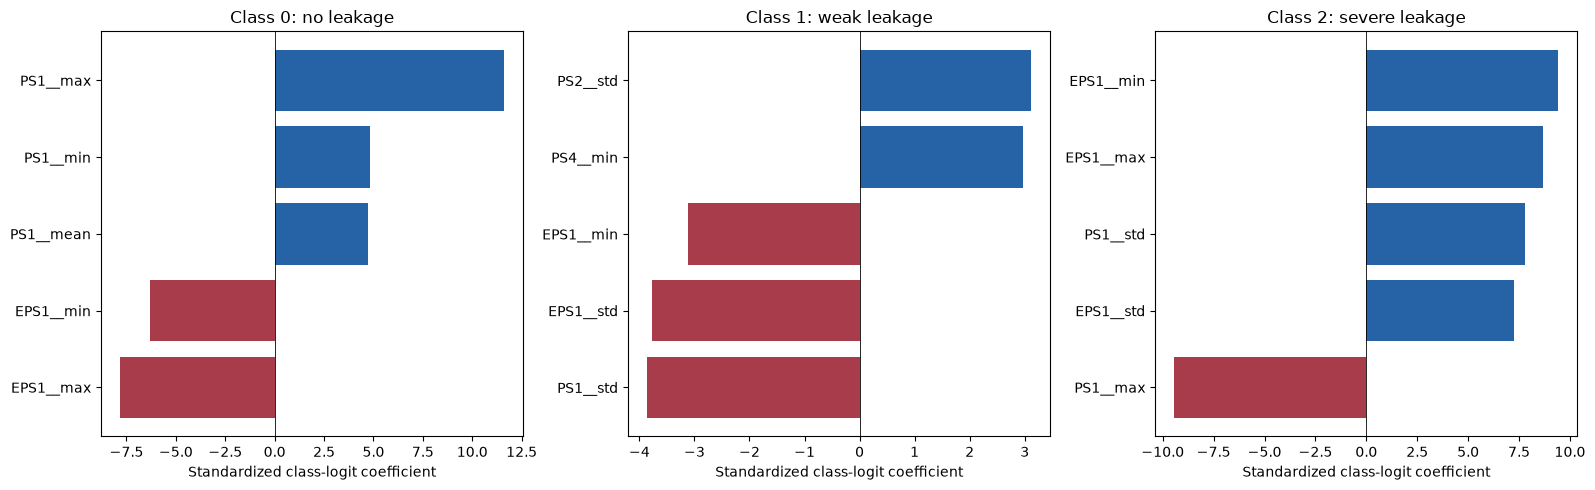

In [6]:
coefficients = standardized_coefficients(ROOT)
display(coefficients)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for label, ax in zip([0, 1, 2], axes, strict=True):
    rows = (
        coefficients[coefficients["class"] == label]
        .nlargest(5, "absolute_coefficient")
        .sort_values("coefficient")
    )
    ax.barh(
        rows["feature"],
        rows["coefficient"],
        color=["#2563a6" if v >= 0 else "#a83c4b" for v in rows["coefficient"]],
    )
    ax.axvline(0, color="black", linewidth=0.6)
    ax.set(
        title=f"Class {label}: " + rows.iloc[0]["label"],
        xlabel="Standardized class-logit coefficient",
    )
fig.tight_layout()
plt.show()

## Reproduction and deployment boundary

Use `scripts/reproduce_training.py --output data/processed/reproductions/review-1` after the verified download. It accepts a fresh acquisition timestamp only for the same pinned archive/content, trains only the saved development membership and writes a separate non-official bundle. Historical reproduction entry points retain their original exact-provenance checks. Docker serves only the official bundle; the reproduction never replaces it. Read README, `docs/release-readiness.md` and `docs/requirements-checklist.md` for the actual clean-copy run, deployment screenshot and remaining publication steps.

In [7]:
history = verify_review_history(ROOT)
print(
    "PASS:",
    len(history["files"]),
    "historical byte checks unchanged; no training or test prediction in this notebook.",
)

PASS: 72 historical byte checks unchanged; no training or test prediction in this notebook.
